In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import pickle

# ==================================================
# 1️⃣ VERİ YÜKLE & TEMİZLE
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 1: Veri Yükleme ve Ön Temizlik")
print("="*50)

df = pd.read_csv("3.csv")
print(f"✅ CSV Dosyası Okundu. İlk Durum: {df.shape[0]} satır, {df.shape[1]} sütun.")

# Gereksizleri at
if df.columns[0] == "Unnamed: 0": 
    df = df.iloc[:, 1:]

drop_cols = ["İlan No", "Kimden"]
dropped_count = 0
for c in drop_cols:
    if c in df.columns:
        df.drop(c, axis=1, inplace=True)
        dropped_count += 1
print(f"🗑️  Gereksiz {dropped_count} sütun (İlan No, Kimden vb.) atıldı.")

# Sayısal Temizlik
def clean_numeric(x):
    if isinstance(x, str): x = x.replace(" km", "").replace(" TL", "").replace(".", "").strip()
    try: return int(x)
    except: return np.nan

print("🧼 Metinsel ifadeler (km, TL, nokta) temizleniyor...")
df["Fiyat"] = df["Fiyat"].apply(clean_numeric)
df["Kilometre"] = df["Kilometre"].apply(clean_numeric)
df["Yıl"] = df["Yıl"].apply(clean_numeric)

initial_len = len(df)
df.dropna(subset=["Fiyat", "Kilometre", "Yıl"], inplace=True)
print(f"🧹 Boş veriler temizlendi. ({initial_len - len(df)} satır silindi)")

# Mantıksız verileri at
print("📉 Aykırı değerler (Çok ucuz/pahalı) filtreleniyor...")
df = df[(df["Fiyat"] > 50000) & (df["Fiyat"] < 20000000)]
df["Yaş"] = 2025 - df["Yıl"]
print(f"✅ Temizlik Bitti. Kalan Veri: {len(df)} satır.")

# ==================================================
# 2️⃣ KRİTİK HAMLE: BAZ FİYAT (Target Encoding) ⭐
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 2: Baz Fiyat (Piyasa Değeri) Analizi")
print("="*50)

# Her modelin hasarsız/ortalama piyasa değerini hesaplayıp sözlüğe atıyoruz.
df["Grup_ID"] = df["Marka"].astype(str) + "|" + df["Seri"].astype(str) + "|" + df["Model"].astype(str) + "|" + df["Yaş"].astype(str)

# Ortalama fiyatları hesapla
print("🧮 Her araç grubu için ortalama piyasa fiyatı hesaplanıyor...")
baz_fiyatlar = df.groupby("Grup_ID")["Fiyat"].median().to_dict()
print(f"📊 Toplam {len(baz_fiyatlar)} farklı araç grubu (ID) tespit edildi.")

# Veri setine "Baz_Fiyat" sütunu ekle
def get_baz_fiyat(x):
    return baz_fiyatlar.get(x, df["Fiyat"].median()) 

df["Baz_Fiyat"] = df["Grup_ID"].apply(get_baz_fiyat)
print("✅ Her satıra 'Baz_Fiyat' bilgisi işlendi.")

# Renk Encode
print("🎨 Renkler sayısal kodlara çevriliyor...")
from sklearn.preprocessing import LabelEncoder
le_renk = LabelEncoder()
df["Renk"] = df["Renk"].astype(str)
df["Renk_Encoded"] = le_renk.fit_transform(df["Renk"])

# ==================================================
# 3️⃣ AĞIRLIKLI HASAR PUANI
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 3: Hasar Puanlama Sistemi")
print("="*50)

not_kaporta = ["Fiyat", "Kilometre", "Yaş", "Grup_ID", "Baz_Fiyat", "Renk", "Renk_Encoded", "Marka", "Seri", "Model", "Yıl"]
kaporta_cols = [c for c in df.columns if c not in not_kaporta]
print(f"🛠️  İncelenecek Kaporta Parçası Sayısı: {len(kaporta_cols)}")

weights = { "Tavan": 4.0, "Motor Kaputu": 2.5, "Şasi": 5.0, "Podye": 5.0, "Direk": 4.0 }
print(f"⚖️  Ağırlıklar uygulandı (Tavan: 4.0x, Kaput: 2.5x vb.)")

def get_hasar_skoru(row):
    total_loss = 0.0
    for col in kaporta_cols:
        val = str(row[col]).lower()
        score = 0.0
        if "değiş" in val: score = 1.0
        elif "lokal" in val: score = 0.15
        elif "boya" in val: score = 0.30
        weight = weights.get(col, 1.0)
        total_loss += (score * weight)
    return total_loss

df["Toplam_Hasar"] = df.apply(get_hasar_skoru, axis=1)
print("✅ Tüm araçların hasar skorları hesaplandı.")

# ==================================================
# 4️⃣ SCALE & HAZIRLIK
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 4: Veriyi Modele Hazırlama")
print("="*50)

input_cols = ["Kilometre", "Yaş", "Baz_Fiyat", "Renk_Encoded", "Toplam_Hasar"]
print(f"📥 Modele Girecek Sütunlar: {input_cols}")

X = df[input_cols].values
y = df["Fiyat"].values

# Log dönüşümü
print("📐 Fiyat ve Baz Fiyat için LOG dönüşümü yapılıyor (Dengesizliği önlemek için)...")
y_log = np.log1p(y)
X[:, 2] = np.log1p(X[:, 2]) 

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
print("📏 Veriler 0-1 arasına sıkıştırıldı (Scaling).")

# Kaydet
encoders = {
    "baz_fiyatlar": baz_fiyatlar,
    "le_renk": le_renk,
    "scaler": scaler,
    "kaporta_cols": kaporta_cols,
    "weights": weights,
    "input_cols": input_cols,
    "global_mean": df["Fiyat"].median()
}
with open("encoders_v5.pkl", "wb") as f:
    pickle.dump(encoders, f)
print("💾 Encoderlar ve Sözlükler 'encoders_v5.pkl' dosyasına kaydedildi.")

# ==================================================
# 5️⃣ MODEL EĞİTİMİ
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 5: Yapay Zeka Eğitimi Başlıyor")
print("="*50)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_log, test_size=0.15, random_state=42)
print(f"🏋️ Eğitim Verisi: {len(X_train)} adet | 🧪 Test Verisi: {len(X_test)} adet")

model = Sequential([
    Dense(64, activation="relu", input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(optimizer=Adam(learning_rate=0.005), loss="mse", metrics=["mae"])

early = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15)

print("🚀 Model eğitiliyor... (Bu işlem biraz sürebilir)")
# Verbose 1 yaptım ki eğitim çubuğunu da gör
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=500, batch_size=64, callbacks=[early, reduce_lr], verbose=1)
print("✅ Eğitim tamamlandı!")

# ==================================================
# 6️⃣ SONUÇ
# ==================================================
print("\n" + "="*50)
print("⏳ ADIM 6: Performans Ölçümü ve Kayıt")
print("="*50)

y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_real = np.expm1(y_test)

r2 = r2_score(y_real, y_pred)
mae = mean_absolute_error(y_real, y_pred)

print(f"\n🔥 v5 FİNAL SONUÇLARI")
print(f"✅ R² Score (Başarı): {r2:.4f}")
print(f"✅ Ortalama Sapma (Hata): {int(mae):,} TL")

# TFLite Kayıt
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
with open("car_price_model_v5.tflite", "wb") as f:
    f.write(tflite_model)

print("\n💾 TFLite modeli 'car_price_model_v5.tflite' olarak kaydedildi.")
print("🏁 İŞLEM BAŞARIYLA TAMAMLANDI ")


⏳ ADIM 1: Veri Yükleme ve Ön Temizlik
✅ CSV Dosyası Okundu. İlk Durum: 4716 satır, 22 sütun.
🗑️  Gereksiz 2 sütun (İlan No, Kimden vb.) atıldı.
🧼 Metinsel ifadeler (km, TL, nokta) temizleniyor...
🧹 Boş veriler temizlendi. (1 satır silindi)
📉 Aykırı değerler (Çok ucuz/pahalı) filtreleniyor...
✅ Temizlik Bitti. Kalan Veri: 4555 satır.

⏳ ADIM 2: Baz Fiyat (Piyasa Değeri) Analizi
🧮 Her araç grubu için ortalama piyasa fiyatı hesaplanıyor...
📊 Toplam 1303 farklı araç grubu (ID) tespit edildi.
✅ Her satıra 'Baz_Fiyat' bilgisi işlendi.
🎨 Renkler sayısal kodlara çevriliyor...

⏳ ADIM 3: Hasar Puanlama Sistemi
🛠️  İncelenecek Kaporta Parçası Sayısı: 13
⚖️  Ağırlıklar uygulandı (Tavan: 4.0x, Kaput: 2.5x vb.)
✅ Tüm araçların hasar skorları hesaplandı.

⏳ ADIM 4: Veriyi Modele Hazırlama
📥 Modele Girecek Sütunlar: ['Kilometre', 'Yaş', 'Baz_Fiyat', 'Renk_Encoded', 'Toplam_Hasar']
📐 Fiyat ve Baz Fiyat için LOG dönüşümü yapılıyor (Dengesizliği önlemek için)...
📏 Veriler 0-1 arasına sıkıştırıldı (Scal

C:\Users\Er\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


61/61 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 52.4241 - mae: 5.4582 - val_loss: 51.3129 - val_mae: 7.1257 - learning_rate: 0.0050
Epoch 2/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7662 - mae: 0.6792 - val_loss: 26.5260 - val_mae: 5.0897 - learning_rate: 0.0050
Epoch 3/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4752 - mae: 0.5490 - val_loss: 21.1736 - val_mae: 4.5341 - learning_rate: 0.0050
Epoch 4/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3974 - mae: 0.4945 - val_loss: 13.7975 - val_mae: 3.6324 - learning_rate: 0.0050
Epoch 5/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3438 - mae: 0.4610 - val_loss: 9.2062 - val_mae: 2.9428 - learning_rate: 0.0050
Epoch 6/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2004 - mae: 0.3460 - val_loss: 7.2191 - val_mae: 2.5875 - learning_rate: 0.0050
Epoch 7/500
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1710 - mae: 0.3262 - val_loss: 4.3394 - val_mae: 1.9794 - learning_rate: 0.0050
Epoch 8/500
61/61 ━━

INFO:tensorflow:Assets written to: C:\Users\Er\AppData\Local\Temp\tmpjc9k_ud7\assets


Saved artifact at 'C:\Users\Er\AppData\Local\Temp\tmpjc9k_ud7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 5), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1750124902544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124903312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124902736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124903120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124902352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124902928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124903696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124898896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124903504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124901968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1750124904080: Ten

In [4]:
import pandas as pd
import numpy as np
import tensorflow.lite as tflite
import pickle
import random

# ==================================================
# ⚙️ AYARLAR
# ==================================================
CSV_PATH = "3.csv"
MODEL_PATH = "car_price_model_v5.tflite"
ENCODER_PATH = "encoders_v5.pkl"

# ==================================================
# 🛠️ YARDIMCI FONKSİYONLAR
# ==================================================
def clean_numeric(x):
    if isinstance(x, str):
        x = x.replace(" km", "").replace(" TL", "").replace(".", "").strip()
    try:
        return int(x)
    except:
        return 0

def calculate_damage_score(parts_dict, weights):
    """
    Verilen parça sözlüğüne göre toplam hasar puanını hesaplar.
    """
    total_loss = 0.0
    for parca, durum in parts_dict.items():
        durum = str(durum).lower()
        score = 0.0
        
        if "değiş" in durum: score = 1.0     # Büyük Ceza
        elif "lokal" in durum: score = 0.15  # Küçük Ceza
        elif "boya" in durum: score = 0.30   # Orta Ceza
        
        w = weights.get(parca, 1.0)
        total_loss += (score * w)
    return total_loss

def run_prediction(interpreter, input_details, output_details, scaler, input_vector):
    # Veriyi Scale et
    input_scaled = scaler.transform(np.array([input_vector])).astype(np.float32)
    
    # Modele ver
    interpreter.set_tensor(input_details[0]['index'], input_scaled)
    interpreter.invoke()
    
    # Çıktıyı al (Log -> TL dönüşümü)
    log_pred = interpreter.get_tensor(output_details[0]['index'])[0][0]
    return np.expm1(log_pred)

# ==================================================
# 1️⃣ YÜKLEME
# ==================================================
print("⏳ Dosyalar ve Model yükleniyor...")

# TFLite
interpreter = tflite.Interpreter(model_path=MODEL_PATH)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Encoders
with open(ENCODER_PATH, "rb") as f:
    enc = pickle.load(f)

scaler = enc["scaler"]
baz_fiyatlar = enc["baz_fiyatlar"]
le_renk = enc["le_renk"]
kaporta_cols = enc["kaporta_cols"]
weights = enc["weights"]
global_mean = enc["global_mean"]

# CSV
df_raw = pd.read_csv(CSV_PATH)
if df_raw.columns[0] == "Unnamed: 0":
    df_raw = df_raw.iloc[:, 1:]

# ==================================================
# 2️⃣ SİMÜLASYON DÖNGÜSÜ
# ==================================================
while True:
    print("\n" + "="*60)
    user_input = input("👉 İncelemek için İndex No gir (Çıkış 'q'): ")
    
    if user_input.lower() == 'q':
        break
        
    try:
        idx = int(user_input)
        if idx < 0 or idx >= len(df_raw):
            print("❌ Geçersiz İndex!")
            continue

        row = df_raw.iloc[idx]
        
        # ------------------------------------------------
        # ADIM 1: BÜTÜN BİLGİLERİ DÖK
        # ------------------------------------------------
        print(f"\n📄 --- {idx} NUMARALI ARAÇ BİLGİLERİ ---")
        for col in df_raw.columns:
            print(f"🔸 {col.ljust(20)} : {row[col]}")
            
        actual_price = clean_numeric(row["Fiyat"])
        
        # ------------------------------------------------
        # ADIM 2: ORİJİNAL TAHMİN HAZIRLIĞI
        # ------------------------------------------------
        km = clean_numeric(row["Kilometre"])
        yas = 2025 - clean_numeric(row["Yıl"])
        
        # Baz Fiyat Bul
        grup_id = f"{row['Marka']}|{row['Seri']}|{row['Model']}|{yas}"
        baz_fiyat = baz_fiyatlar.get(grup_id, global_mean)
        
        # Renk Kodla
        renk_str = str(row["Renk"])
        renk_enc = le_renk.transform([renk_str])[0] if renk_str in le_renk.classes_ else 0
        
        # Kaporta Durumunu Sözlüğe Çek
        current_parts = {}
        for col in kaporta_cols:
            val = row[col] if col in row else "Orijinal"
            current_parts[col] = val
            
        # Orijinal Hasar Skoru
        damage_score_1 = calculate_damage_score(current_parts, weights)
        
        # Tahmin 1
        # Vektör: [KM, Yaş, Baz(Log), Renk, Hasar]
        vec_1 = [km, yas, np.log1p(baz_fiyat), renk_enc, damage_score_1]
        pred_1 = run_prediction(interpreter, input_details, output_details, scaler, vec_1)
        
        print("\n" + "-"*40)
        print(f"💰 1. TAHMİN (MEVCUT DURUM)")
        print(f"   Hasar Skoru: {damage_score_1:.2f}")
        print(f"   Tahmin: {pred_1:,.0f} TL")
        if actual_price > 0:
            print(f"   Gerçek: {actual_price:,.0f} TL")
        
        # ------------------------------------------------
        # ADIM 3: RASTGELE PARÇA DEĞİŞİMİ (SİMÜLASYON)
        # ------------------------------------------------
        print("\n🎲 --- SİMÜLASYON BAŞLIYOR ---")
        
        # Rastgele bir parça seç
        random_part = random.choice(kaporta_cols)
        original_status = current_parts[random_part]
        
        # Olası durumlar (Mevcut durum hariç)
        options = ["Orijinal", "Boyalı", "Değişmiş"]
        # Basit bir filtreleme: Mevcut durum neyse onu seçeneklerden çıkaralım ki değişiklik olsun
        # (Tam eşleşme olmayabilir string temizliği yüzünden ama basitçe random atalım)
        new_status = random.choice(options)
        
        # Sözlüğü güncelle
        simulated_parts = current_parts.copy()
        simulated_parts[random_part] = new_status
        
        print(f"⚡ DEĞİŞİKLİK YAPILDI: '{random_part}'")
        print(f"   Eski Durum: {original_status}")
        print(f"   Yeni Durum: {new_status}")
        
        # Yeni Hasar Skoru
        damage_score_2 = calculate_damage_score(simulated_parts, weights)
        
        # Tahmin 2
        vec_2 = [km, yas, np.log1p(baz_fiyat), renk_enc, damage_score_2]
        pred_2 = run_prediction(interpreter, input_details, output_details, scaler, vec_2)
        
        print("\n💰 2. TAHMİN (SİMÜLASYON)")
        print(f"   Yeni Hasar Skoru: {damage_score_2:.2f}")
        print(f"   Yeni Tahmin: {pred_2:,.0f} TL")
        
        # ------------------------------------------------
        # ADIM 4: KIYASLAMA
        # ------------------------------------------------
        diff = pred_2 - pred_1
        
        print("\n📊 SONUÇ:")
        if diff < 0:
            print(f"📉 Fiyat {abs(diff):,.0f} TL DÜŞTÜ.")
        elif diff > 0:
            print(f"📈 Fiyat {diff:,.0f} TL ARTTI.")
        else:
            print("Feature (Özellik) fiyatı etkilemedi.")
            
    except Exception as e:
        print(f"❌ Hata: {e}")
        import traceback
        traceback.print_exc()

C:\Users\Er\anaconda3\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


⏳ Dosyalar ve Model yükleniyor...



👉 İncelemek için İndex No gir (Çıkış 'q'):  2261



📄 --- 2261 NUMARALI ARAÇ BİLGİLERİ ---
🔸 Kimden               : Galeriden
🔸 Marka                : Fiat
🔸 Seri                 : Egea
🔸 Model                : 1.6 Multijet Easy
🔸 Yıl                  : 2019
🔸 Kilometre            : 142.312 km
🔸 Renk                 : Beyaz
🔸 Fiyat                : 865000 TL
🔸 Sağ Arka Çamurluk    : Orijinal
🔸 Arka Kaput           : Boyanmış
🔸 Sol Arka Çamurluk    : Boyanmış
🔸 Sağ Arka Kapı        : Boyanmış
🔸 Sağ Ön Kapı          : Orijinal
🔸 Tavan                : Orijinal
🔸 Sol Arka Kapı        : Boyanmış
🔸 Sol Ön Kapı          : Orijinal
🔸 Sağ Ön Çamurluk      : Değişmiş
🔸 Motor Kaputu         : Orijinal
🔸 Sol Ön Çamurluk      : Orijinal
🔸 Ön Tampon            : Orijinal
🔸 Arka Tampon          : Orijinal
🔸 İlan No              : Orijinal

----------------------------------------
💰 1. TAHMİN (MEVCUT DURUM)
   Hasar Skoru: 2.20
   Tahmin: 772,403 TL
   Gerçek: 865,000 TL

🎲 --- SİMÜLASYON BAŞLIYOR ---
⚡ DEĞİŞİKLİK YAPILDI: 'Sağ Arka Çamurluk'
   Eski

👉 İncelemek için İndex No gir (Çıkış 'q'):  2230



📄 --- 2230 NUMARALI ARAÇ BİLGİLERİ ---
🔸 Kimden               : Galeriden
🔸 Marka                : Fiat
🔸 Seri                 : Egea
🔸 Model                : 1.3 Multijet Easy
🔸 Yıl                  : 2017
🔸 Kilometre            : 170.000 km
🔸 Renk                 : Beyaz
🔸 Fiyat                : 750000 TL
🔸 Sağ Arka Çamurluk    : Orijinal
🔸 Arka Kaput           : Orijinal
🔸 Sol Arka Çamurluk    : Orijinal
🔸 Sağ Arka Kapı        : Orijinal
🔸 Sağ Ön Kapı          : Orijinal
🔸 Tavan                : Orijinal
🔸 Sol Arka Kapı        : Orijinal
🔸 Sol Ön Kapı          : Orijinal
🔸 Sağ Ön Çamurluk      : Orijinal
🔸 Motor Kaputu         : Orijinal
🔸 Sol Ön Çamurluk      : Orijinal
🔸 Ön Tampon            : Orijinal
🔸 Arka Tampon          : Orijinal
🔸 İlan No              : Orijinal

----------------------------------------
💰 1. TAHMİN (MEVCUT DURUM)
   Hasar Skoru: 0.00
   Tahmin: 947,345 TL
   Gerçek: 750,000 TL

🎲 --- SİMÜLASYON BAŞLIYOR ---
⚡ DEĞİŞİKLİK YAPILDI: 'Sağ Ön Çamurluk'
   Eski D

KeyboardInterrupt: Interrupted by user

In [6]:
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import r2_score, mean_absolute_error

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.optimizers import Adam

import pickle



# ==================================================

# 1️⃣ VERİ YÜKLE & TEMİZLE

# ==================================================

print("⏳ Veri yükleniyor...")

df = pd.read_csv("3.csv")



# Gereksizleri at

if df.columns[0] == "Unnamed: 0": df = df.iloc[:, 1:]

drop_cols = ["İlan No", "Kimden"]

df.drop([c for c in drop_cols if c in df.columns], axis=1, inplace=True)



# Sayısal Temizlik

def clean_numeric(x):

    if isinstance(x, str): x = x.replace(" km", "").replace(" TL", "").replace(".", "").strip()

    try: return int(x)

    except: return np.nan



df["Fiyat"] = df["Fiyat"].apply(clean_numeric)

df["Kilometre"] = df["Kilometre"].apply(clean_numeric)

df["Yıl"] = df["Yıl"].apply(clean_numeric)

df.dropna(subset=["Fiyat", "Kilometre", "Yıl"], inplace=True)



# Mantıksız verileri at

df = df[(df["Fiyat"] > 50000) & (df["Fiyat"] < 20000000)]

df["Yaş"] = 2025 - df["Yıl"]



# ==================================================

# 2️⃣ KRİTİK HAMLE: BAZ FİYAT (Target Encoding) ⭐

# ==================================================

# Her modelin hasarsız/ortalama piyasa değerini hesaplayıp sözlüğe atıyoruz.

# Marka+Seri+Model+Yıl birleşimi bize o arabanın ortalama fiyatını verir.

df["Grup_ID"] = df["Marka"].astype(str) + "|" + df["Seri"].astype(str) + "|" + df["Model"].astype(str) +
"|" + df["Yaş"].astype(str)



# Ortalama fiyatları hesapla

baz_fiyatlar = df.groupby("Grup_ID")["Fiyat"].median().to_dict()



# Veri setine "Baz_Fiyat" sütunu ekle (Model bu değere bakıp yönünü bulacak)

def get_baz_fiyat(x):

    return baz_fiyatlar.get(x, df["Fiyat"].median()) # Bulamazsa genel ortalamayı ver



df["Baz_Fiyat"] = df["Grup_ID"].apply(get_baz_fiyat)



# Artık Marka, Seri, Model sütunlarına ihtiyacımız yok (Çünkü Baz_Fiyat onların özetidir)

# Renk kalsın, ufak etkisi olabilir.

from sklearn.preprocessing import LabelEncoder

le_renk = LabelEncoder()

df["Renk"] = df["Renk"].astype(str)

df["Renk_Encoded"] = le_renk.fit_transform(df["Renk"])



# ==================================================

# 3️⃣ AĞIRLIKLI HASAR PUANI

# ==================================================

not_kaporta = ["Fiyat", "Kilometre", "Yaş", "Grup_ID", "Baz_Fiyat", "Renk", "Renk_Encoded",
               "Marka", "Seri", "Model", "Yıl"]

kaporta_cols = [c for c in df.columns if c not in not_kaporta]



weights = { "Tavan": 4.0, "Motor Kaputu": 2.5, "Şasi": 5.0, "Podye": 5.0, "Direk": 4.0 }



def get_hasar_skoru(row):

    total_loss = 0.0

    for col in kaporta_cols:

        val = str(row[col]).lower()

        score = 0.0 # Hasar puanı (0 temiz, yüksek kötü)

        

        if "değiş" in val: score = 1.0

        elif "lokal" in val: score = 0.15

        elif "boya" in val: score = 0.30

        

        weight = weights.get(col, 1.0)

        total_loss += (score * weight)

    return total_loss



df["Toplam_Hasar"] = df.apply(get_hasar_skoru, axis=1)



# ==================================================

# 4️⃣ SCALE & HAZIRLIK

# ==================================================

# Modele girecek sütunlar: [Kilometre, Yaş, Baz_Fiyat, Renk_Encoded, Toplam_Hasar]

input_cols = ["Kilometre", "Yaş", "Baz_Fiyat", "Renk_Encoded", "Toplam_Hasar"]



X = df[input_cols].values

y = df["Fiyat"].values



# Log dönüşümü (Fiyat dengesizliği için şart)

y_log = np.log1p(y)

# Baz fiyatı da log'a çevirelim ki model oran kurabilsin

X[:, 2] = np.log1p(X[:, 2]) 



scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)



# Kaydet

encoders = {

    "baz_fiyatlar": baz_fiyatlar, # ⭐ Bunu testte ve mobilde kullanacağız

    "le_renk": le_renk,

    "scaler": scaler,

    "kaporta_cols": kaporta_cols,

    "weights": weights,

    "input_cols": input_cols,

    "global_mean": df["Fiyat"].median()

}

with open("encoders_v5.pkl", "wb") as f:

    pickle.dump(encoders, f)



# ==================================================

# 5️⃣ MODEL EĞİTİMİ

# ==================================================

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_log, test_size=0.15, random_state=42)



model = Sequential([

    Dense(64, activation="relu", input_dim=X_train.shape[1]),

    BatchNormalization(),

    Dense(32, activation="relu"),

    Dense(16, activation="relu"),

    Dense(1, activation="linear")

])



# Daha basit model, çünkü "Baz_Fiyat" zaten cevabın %90'ı. Model sadece ince ayar yapacak.

model.compile(optimizer=Adam(learning_rate=0.005), loss="mse", metrics=["mae"])



early = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15)



print("🚀 Model eğitiliyor (Baz Fiyat Destekli)...")

model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=500, batch_size=64, callbacks=[early, reduce_lr], verbose=0)



# ==================================================

# 6️⃣ SONUÇ

# ==================================================

y_pred_log = model.predict(X_test)

y_pred = np.expm1(y_pred_log)

y_real = np.expm1(y_test)



r2 = r2_score(y_real, y_pred)

mae = mean_absolute_error(y_real, y_pred)



print(f"\n🔥 v5 SONUCU (BAZ FİYATLI)")

print(f"✅ R² Score: {r2:.4f}")

print(f"✅ Ort. Hata: {int(mae)} TL")



# TFLite Kayıt

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("car_price_model_v5.tflite", "wb") as f:

    f.write(tflite_model)

⏳ Veri yükleniyor...


C:\Users\Er\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


🚀 Model eğitiliyor (Baz Fiyat Destekli)...
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 

🔥 v5 SONUCU (BAZ FİYATLI)
✅ R² Score: 0.9926
✅ Ort. Hata: 75625 TL
INFO:tensorflow:Assets written to: C:\Users\Er\AppData\Local\Temp\tmprdsdddrg\assets


INFO:tensorflow:Assets written to: C:\Users\Er\AppData\Local\Temp\tmprdsdddrg\assets


Saved artifact at 'C:\Users\Er\AppData\Local\Temp\tmprdsdddrg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 5), dtype=tf.float32, name='keras_tensor_6')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1748105019216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748105018256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106297808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106298960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748105015760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748105018640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106299152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106299728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106299344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106300304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1748106299920: T

In [ ]:
import pandas as pd
import numpy as np
import tensorflow.lite as tflite
import pickle
import random

# ==================================================
# ⚙️ AYARLAR
# ==================================================
CSV_PATH = "3.csv"
MODEL_PATH = "car_price_model_v5.tflite"
ENCODER_PATH = "encoders_v5.pkl"

# ==================================================
# 🛠️ YARDIMCI FONKSİYONLAR
# ==================================================
def clean_numeric(x):
    if isinstance(x, str):
        x = x.replace(" km", "").replace(" TL", "").replace(".", "").strip()
    try:
        return int(x)
    except:
        return 0

def calculate_damage_score(parts_dict, weights):
    """
    Verilen parça sözlüğüne göre toplam hasar puanını hesaplar.
    """
    total_loss = 0.0
    for parca, durum in parts_dict.items():
        durum = str(durum).lower()
        score = 0.0
        
        if "değiş" in durum: score = 1.0     # Büyük Ceza
        elif "lokal" in durum: score = 0.15  # Küçük Ceza
        elif "boya" in durum: score = 0.30   # Orta Ceza
        
        w = weights.get(parca, 1.0)
        total_loss += (score * w)
    return total_loss

def run_prediction(interpreter, input_details, output_details, scaler, input_vector):
    # Veriyi Scale et
    input_scaled = scaler.transform(np.array([input_vector])).astype(np.float32)
    
    # Modele ver
    interpreter.set_tensor(input_details[0]['index'], input_scaled)
    interpreter.invoke()
    
    # Çıktıyı al (Log -> TL dönüşümü)
    log_pred = interpreter.get_tensor(output_details[0]['index'])[0][0]
    return np.expm1(log_pred)

# ==================================================
# 1️⃣ YÜKLEME
# ==================================================
print("⏳ Dosyalar ve Model yükleniyor...")

# TFLite
interpreter = tflite.Interpreter(model_path=MODEL_PATH)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Encoders
with open(ENCODER_PATH, "rb") as f:
    enc = pickle.load(f)

scaler = enc["scaler"]
baz_fiyatlar = enc["baz_fiyatlar"]
le_renk = enc["le_renk"]
kaporta_cols = enc["kaporta_cols"]
weights = enc["weights"]
global_mean = enc["global_mean"]

# CSV
df_raw = pd.read_csv(CSV_PATH)
if df_raw.columns[0] == "Unnamed: 0":
    df_raw = df_raw.iloc[:, 1:]

# ==================================================
# 2️⃣ SİMÜLASYON DÖNGÜSÜ
# ==================================================
while True:
    print("\n" + "="*60)
    user_input = input("👉 İncelemek için İndex No gir (Çıkış 'q'): ")
    
    if user_input.lower() == 'q':
        break
        
    try:
        idx = int(user_input)
        if idx < 0 or idx >= len(df_raw):
            print("❌ Geçersiz İndex!")
            continue

        row = df_raw.iloc[idx]
        
        # ------------------------------------------------
        # ADIM 1: BÜTÜN BİLGİLERİ DÖK
        # ------------------------------------------------
        print(f"\n📄 --- {idx} NUMARALI ARAÇ BİLGİLERİ ---")
        for col in df_raw.columns:
            print(f"🔸 {col.ljust(20)} : {row[col]}")
            
        actual_price = clean_numeric(row["Fiyat"])
        
        # ------------------------------------------------
        # ADIM 2: ORİJİNAL TAHMİN HAZIRLIĞI
        # ------------------------------------------------
        km = clean_numeric(row["Kilometre"])
        yas = 2025 - clean_numeric(row["Yıl"])
        
        # Baz Fiyat Bul
        grup_id = f"{row['Marka']}|{row['Seri']}|{row['Model']}|{yas}"
        baz_fiyat = baz_fiyatlar.get(grup_id, global_mean)
        
        # Renk Kodla
        renk_str = str(row["Renk"])
        renk_enc = le_renk.transform([renk_str])[0] if renk_str in le_renk.classes_ else 0
        
        # Kaporta Durumunu Sözlüğe Çek
        current_parts = {}
        for col in kaporta_cols:
            val = row[col] if col in row else "Orijinal"
            current_parts[col] = val
            
        # Orijinal Hasar Skoru
        damage_score_1 = calculate_damage_score(current_parts, weights)
        
        # Tahmin 1
        # Vektör: [KM, Yaş, Baz(Log), Renk, Hasar]
        vec_1 = [km, yas, np.log1p(baz_fiyat), renk_enc, damage_score_1]
        pred_1 = run_prediction(interpreter, input_details, output_details, scaler, vec_1)
        
        print("\n" + "-"*40)
        print(f"💰 1. TAHMİN (MEVCUT DURUM)")
        print(f"   Hasar Skoru: {damage_score_1:.2f}")
        print(f"   Tahmin: {pred_1:,.0f} TL")
        if actual_price > 0:
            print(f"   Gerçek: {actual_price:,.0f} TL")
        
        # ------------------------------------------------
        # ADIM 3: RASTGELE PARÇA DEĞİŞİMİ (SİMÜLASYON)
        # ------------------------------------------------
        print("\n🎲 --- SİMÜLASYON BAŞLIYOR ---")
        
        # Rastgele bir parça seç
        random_part = random.choice(kaporta_cols)
        original_status = current_parts[random_part]
        
        # Olası durumlar (Mevcut durum hariç)
        options = ["Orijinal", "Boyalı", "Değişmiş"]
        # Basit bir filtreleme: Mevcut durum neyse onu seçeneklerden çıkaralım ki değişiklik olsun
        # (Tam eşleşme olmayabilir string temizliği yüzünden ama basitçe random atalım)
        new_status = random.choice(options)
        
        # Sözlüğü güncelle
        simulated_parts = current_parts.copy()
        simulated_parts[random_part] = new_status
        
        print(f"⚡ DEĞİŞİKLİK YAPILDI: '{random_part}'")
        print(f"   Eski Durum: {original_status}")
        print(f"   Yeni Durum: {new_status}")
        
        # Yeni Hasar Skoru
        damage_score_2 = calculate_damage_score(simulated_parts, weights)
        
        # Tahmin 2
        vec_2 = [km, yas, np.log1p(baz_fiyat), renk_enc, damage_score_2]
        pred_2 = run_prediction(interpreter, input_details, output_details, scaler, vec_2)
        
        print("\n💰 2. TAHMİN (SİMÜLASYON)")
        print(f"   Yeni Hasar Skoru: {damage_score_2:.2f}")
        print(f"   Yeni Tahmin: {pred_2:,.0f} TL")
        
        # ------------------------------------------------
        # ADIM 4: KIYASLAMA
        # ------------------------------------------------
        diff = pred_2 - pred_1
        
        print("\n📊 SONUÇ:")
        if diff < 0:
            print(f"📉 Fiyat {abs(diff):,.0f} TL DÜŞTÜ.")
        elif diff > 0:
            print(f"📈 Fiyat {diff:,.0f} TL ARTTI.")
        else:
            print("Feature (Özellik) fiyatı etkilemedi.")
            
    except Exception as e:
        print(f"❌ Hata: {e}")
        import traceback
        traceback.print_exc()

C:\Users\Er\anaconda3\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


⏳ Dosyalar ve Model yükleniyor...



👉 İncelemek için İndex No gir (Çıkış 'q'):  2261



📄 --- 2261 NUMARALI ARAÇ BİLGİLERİ ---
🔸 Kimden               : Galeriden
🔸 Marka                : Fiat
🔸 Seri                 : Egea
🔸 Model                : 1.6 Multijet Easy
🔸 Yıl                  : 2019
🔸 Kilometre            : 142.312 km
🔸 Renk                 : Beyaz
🔸 Fiyat                : 865000 TL
🔸 Sağ Arka Çamurluk    : Orijinal
🔸 Arka Kaput           : Boyanmış
🔸 Sol Arka Çamurluk    : Boyanmış
🔸 Sağ Arka Kapı        : Boyanmış
🔸 Sağ Ön Kapı          : Orijinal
🔸 Tavan                : Orijinal
🔸 Sol Arka Kapı        : Boyanmış
🔸 Sol Ön Kapı          : Orijinal
🔸 Sağ Ön Çamurluk      : Değişmiş
🔸 Motor Kaputu         : Orijinal
🔸 Sol Ön Çamurluk      : Orijinal
🔸 Ön Tampon            : Orijinal
🔸 Arka Tampon          : Orijinal
🔸 İlan No              : Orijinal

----------------------------------------
💰 1. TAHMİN (MEVCUT DURUM)
   Hasar Skoru: 2.20
   Tahmin: 809,883 TL
   Gerçek: 865,000 TL

🎲 --- SİMÜLASYON BAŞLIYOR ---
⚡ DEĞİŞİKLİK YAPILDI: 'Sol Ön Çamurluk'
   Eski D

👉 İncelemek için İndex No gir (Çıkış 'q'):  2262



📄 --- 2262 NUMARALI ARAÇ BİLGİLERİ ---
🔸 Kimden               : Galeriden
🔸 Marka                : Fiat
🔸 Seri                 : Egea
🔸 Model                : 1.3 Multijet Easy Stil
🔸 Yıl                  : 2020
🔸 Kilometre            : 58.000 km
🔸 Renk                 : Beyaz
🔸 Fiyat                : 865000 TL
🔸 Sağ Arka Çamurluk    : Orijinal
🔸 Arka Kaput           : Orijinal
🔸 Sol Arka Çamurluk    : Orijinal
🔸 Sağ Arka Kapı        : Orijinal
🔸 Sağ Ön Kapı          : Orijinal
🔸 Tavan                : Orijinal
🔸 Sol Arka Kapı        : Orijinal
🔸 Sol Ön Kapı          : Orijinal
🔸 Sağ Ön Çamurluk      : Boyanmış
🔸 Motor Kaputu         : Orijinal
🔸 Sol Ön Çamurluk      : Değişmiş
🔸 Ön Tampon            : Orijinal
🔸 Arka Tampon          : Orijinal
🔸 İlan No              : Orijinal

----------------------------------------
💰 1. TAHMİN (MEVCUT DURUM)
   Hasar Skoru: 1.30
   Tahmin: 894,237 TL
   Gerçek: 865,000 TL

🎲 --- SİMÜLASYON BAŞLIYOR ---
⚡ DEĞİŞİKLİK YAPILDI: 'Sol Ön Kapı'
   Eski D

👉 İncelemek için İndex No gir (Çıkış 'q'):  2263



📄 --- 2263 NUMARALI ARAÇ BİLGİLERİ ---
🔸 Kimden               : Galeriden
🔸 Marka                : Fiat
🔸 Seri                 : Egea
🔸 Model                : 1.3 Multijet Easy Plus
🔸 Yıl                  : 2023
🔸 Kilometre            : 62.800 km
🔸 Renk                 : Lacivert
🔸 Fiyat                : 975000 TL
🔸 Sağ Arka Çamurluk    : Boyanmış
🔸 Arka Kaput           : Orijinal
🔸 Sol Arka Çamurluk    : Orijinal
🔸 Sağ Arka Kapı        : Değişmiş
🔸 Sağ Ön Kapı          : Boyanmış
🔸 Tavan                : Orijinal
🔸 Sol Arka Kapı        : Orijinal
🔸 Sol Ön Kapı          : Orijinal
🔸 Sağ Ön Çamurluk      : Orijinal
🔸 Motor Kaputu         : Orijinal
🔸 Sol Ön Çamurluk      : Orijinal
🔸 Ön Tampon            : Orijinal
🔸 Arka Tampon          : Orijinal
🔸 İlan No              : Boyanmış

----------------------------------------
💰 1. TAHMİN (MEVCUT DURUM)
   Hasar Skoru: 1.60
   Tahmin: 810,000 TL
   Gerçek: 975,000 TL

🎲 --- SİMÜLASYON BAŞLIYOR ---
⚡ DEĞİŞİKLİK YAPILDI: 'Sağ Arka Kapı'
   E

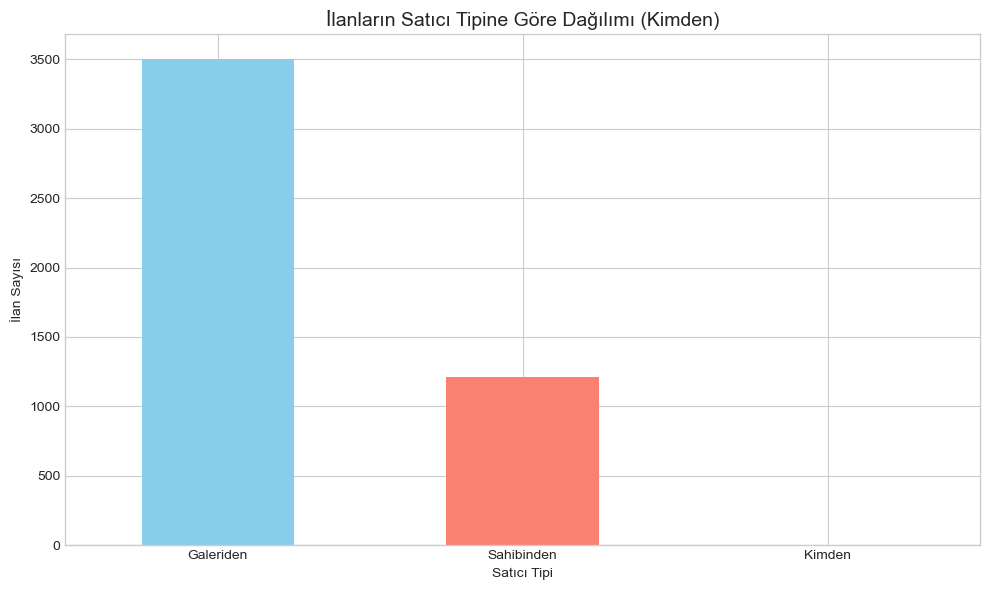

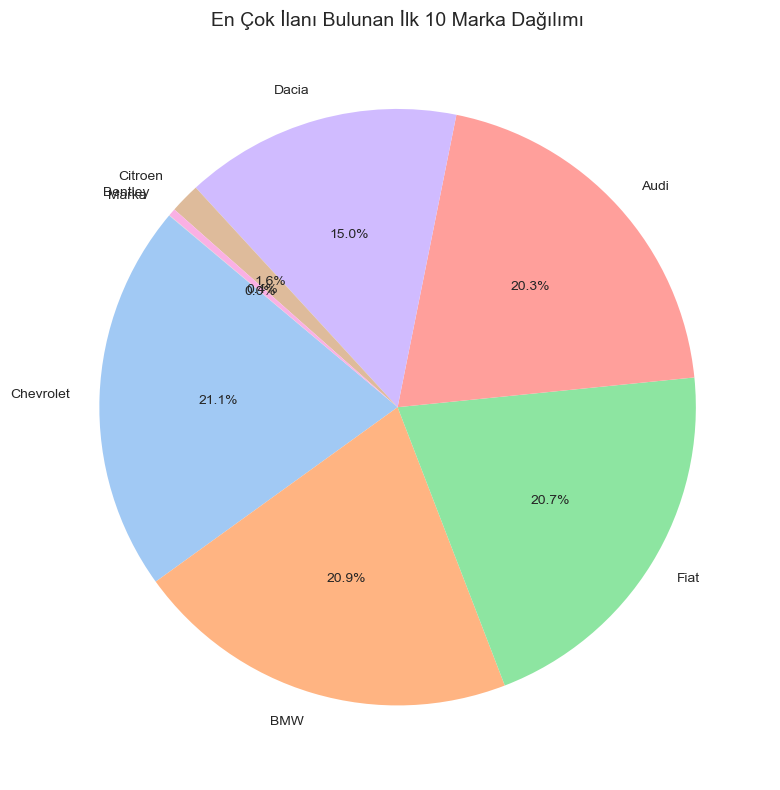

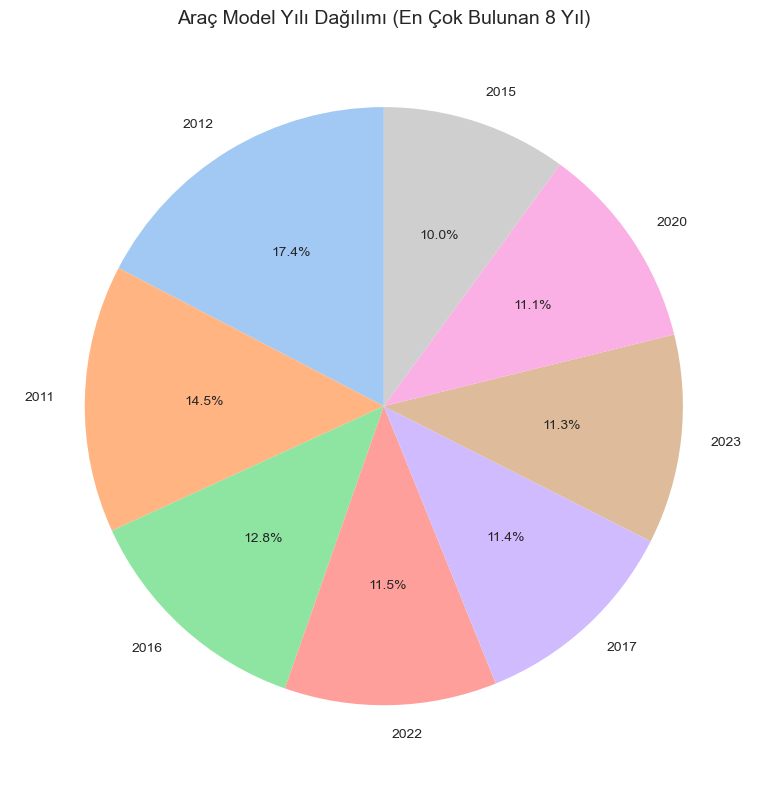

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Veriyi yükle (Dosya adınızı kontrol edin)
df = pd.read_csv("3.csv")

# Görselleştirme ayarları
plt.style.use('seaborn-v0_8-whitegrid') # Daha temiz ve akademik bir görünüm
colors = sns.color_palette('pastel')

# 1️⃣ Kimden (Sütun Grafiği)
plt.figure(figsize=(10, 6))
df['Kimden'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('İlanların Satıcı Tipine Göre Dağılımı (Kimden)', fontsize=14)
plt.xlabel('Satıcı Tipi')
plt.ylabel('İlan Sayısı')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('kimden_sutun.png') # Makaleye koymak için kaydeder
plt.show()

# 2️⃣ Marka (Pasta Grafiği)
plt.figure(figsize=(8, 8))
# Çok fazla marka varsa ilk 10'u göstermek daha okunaklı olur
top_markalar = df['Marka'].value_counts().head(10) 
top_markalar.plot(kind='pie', autopct='%1.1f%%', startangle=140, colors=colors)
plt.title('En Çok İlanı Bulunan İlk 10 Marka Dağılımı', fontsize=14)
plt.ylabel('') # Y ekseni ismini gizle
plt.tight_layout()
plt.savefig('marka_pasta.png')
plt.show()

# 3️⃣ Yıl (Pasta Grafiği)
plt.figure(figsize=(8, 8))
# Yılları gruplandırmak veya en çok bulunan yılları seçmek pasta grafiğinde daha iyi durur
top_yillar = df['Yıl'].value_counts().head(8)
top_yillar.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=colors)
plt.title('Araç Model Yılı Dağılımı (En Çok Bulunan 8 Yıl)', fontsize=14)
plt.ylabel('')
plt.tight_layout()
plt.savefig('yil_pasta.png')
plt.show()

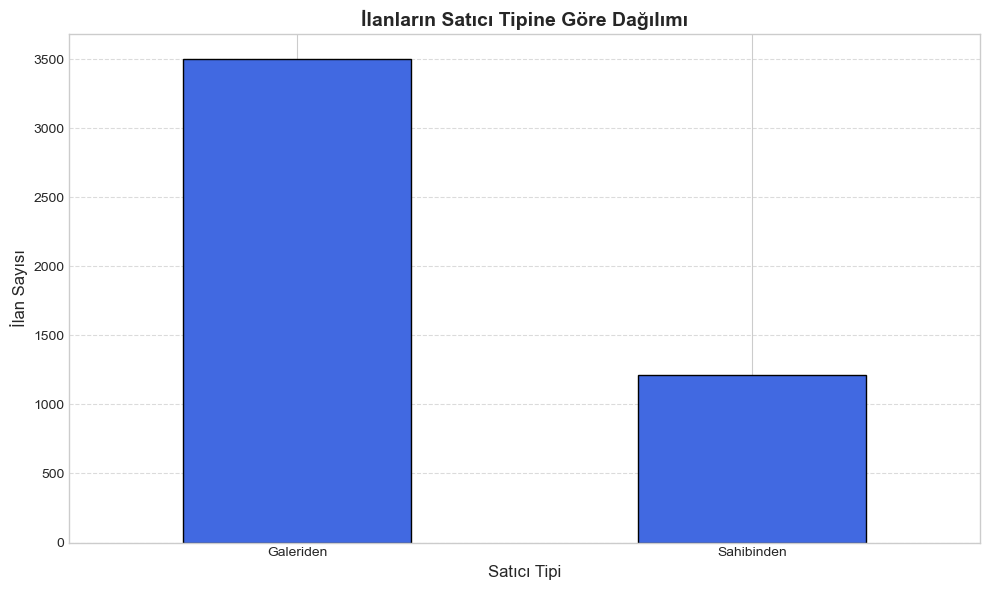

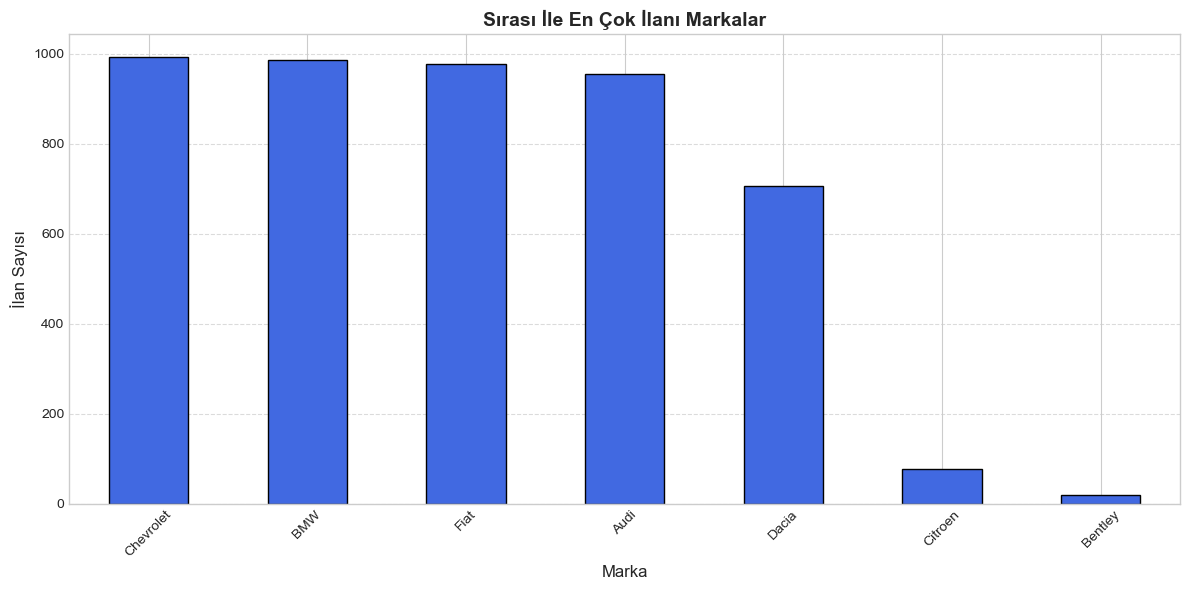

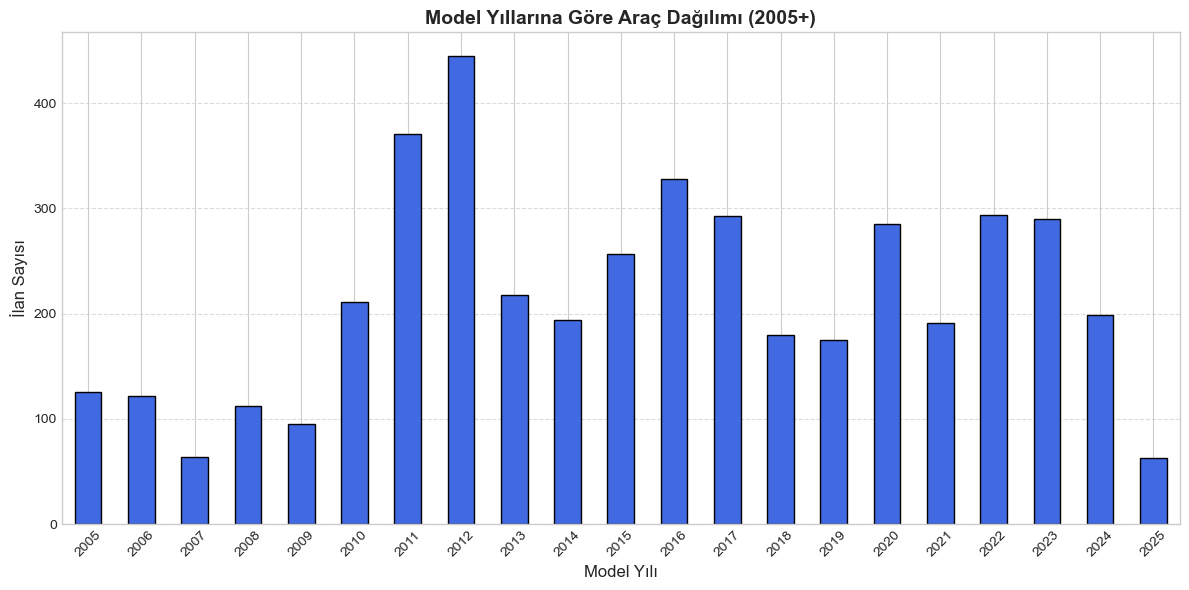

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Veriyi yükle
df = pd.read_csv("3.csv")

# 🛠️ TİP DÖNÜŞTÜRME (Hatanın Çözümü)
# Yıl sütununu sayıya çeviriyoruz, sayıya çevrilemeyenleri (varsa) NaN yapar.
df['Yıl'] = pd.to_numeric(df['Yıl'].astype(str).str.replace('.', ''), errors='coerce')
df = df.dropna(subset=['Yıl']) # Geçersiz yılları temizle
df['Yıl'] = df['Yıl'].astype(int)

# Görselleştirme ayarları
plt.style.use('seaborn-v0_8-muted')
fig_color = "royalblue"

# 1️⃣ Kimden (Sütun Grafiği)
plt.figure(figsize=(10, 6))
df['Kimden'].value_counts().plot(kind='bar', color=fig_color, edgecolor='black')
plt.title('İlanların Satıcı Tipine Göre Dağılımı', fontsize=14, fontweight='bold')
plt.xlabel('Satıcı Tipi', fontsize=12)
plt.ylabel('İlan Sayısı', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('kimden_sutun.png')
plt.show()

# 2️⃣ Marka (Sütun Grafiği - İlk 15)
plt.figure(figsize=(12, 6))
df['Marka'].value_counts().head(15).plot(kind='bar', color=fig_color, edgecolor='black')
plt.title('Sırası İle En Çok İlanı Markalar', fontsize=14, fontweight='bold')
plt.xlabel('Marka', fontsize=12)
plt.ylabel('İlan Sayısı', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('marka_sutun.png')
plt.show()

# 3️⃣ Yıl (Sütun Grafiği - 2005 ve Sonrası)
plt.figure(figsize=(12, 6))
# Yılları saydıktan sonra index'i (yani yılları) sayıya zorlayıp filtreliyoruz
yil_counts = df['Yıl'].value_counts().sort_index()
yil_dagilimi = yil_counts[yil_counts.index >= 2005] 

yil_dagilimi.plot(kind='bar', color=fig_color, edgecolor='black')
plt.title('Model Yıllarına Göre Araç Dağılımı (2005+)', fontsize=14, fontweight='bold')
plt.xlabel('Model Yılı', fontsize=12)
plt.ylabel('İlan Sayısı', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('yil_sutun.png')
plt.show()